# List 1: PyTorch & Training Fundamentals

Labs: Mon 5 Oct, Mon 12 Oct 2026 · Due: Sun 18 Oct 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the four given functions, because later lists reuse them (check them with Materials, Appendix A).
- Background and the PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Individual work. Name the AI tools you used at the top of your solution.

**AI tools used:** Claude (Anthropic) — used to help write and explain the code.

The solutions follow the course *Materials for List 1* (`materials01.ipynb`); each task cites the section it uses as **Materials X.Y** (and **Appendix A** for the four reusable functions). The materials themselves follow Raschka, *Build a Large Language Model (From Scratch)*, Appendix A, and Jurafsky & Martin, *Speech and Language Processing*, chapter "N-gram Language Models".

In [6]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader

Extra imports used throughout the notebook (NumPy, Matplotlib, `Dataset` tools, `math`).

In [7]:
import math
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, TensorDataset, random_split

## Lab 1

### 1.1 Tensors

- Write down the expected shapes of five operations (covering reshape, transpose, `@`, `*` and broadcasting, one of them a broadcast that fails), then run them. Explain the failure.
- Show a case where `view` fails and `reshape` works, and explain it with strides.
- Show a computation that `float32` gets wrong and `float64` gets right.
- Convert an array from NumPy to PyTorch and back. Show which conversions share memory, and which dtype each library uses by default.

**What I do** (background: Materials 1.1 — *Operations*, *Broadcasting*, *Memory layout: strides and contiguity*, *Data types and floating point*, *NumPy and PyTorch*)

1. Create two random tensors `A` (2×6) and `B` (3×4), write the expected shape in a comment, then print the real shape.
2. Transpose a 2×3 tensor, inspect its strides and try `view` vs `reshape` (and `.contiguous().view`); check with `.data_ptr()` which result shares memory.
3. Compute $(10^8 + 1) - 10^8$ in both precisions and relate the result to the machine epsilon `torch.finfo(dtype).eps`.
4. Convert a NumPy array to PyTorch with `torch.from_numpy` (shares memory) and `torch.tensor` (copies), and back with `.numpy()`, then modify the original array to see which objects change.

In [8]:
A = torch.randn(2, 6)
B = torch.randn(3, 4)

print(A.reshape(3, 4).shape)        # expected (3, 4): same 12 numbers, new shape
print(A.T.shape)                    # expected (6, 2): the two axes are swapped
print((A @ A.T).shape)              # expected (2, 2): (2, 6) @ (6, 2)
print((B * torch.randn(4)).shape)   # expected (3, 4): the (4,) vector is broadcast over the 3 rows
try:
    B * torch.randn(3)              # expected: error, last dims 4 and 3 do not match
except RuntimeError as e:
    print("RuntimeError:", e)

torch.Size([3, 4])
torch.Size([6, 2])
torch.Size([2, 2])
torch.Size([3, 4])
RuntimeError: The size of tensor a (4) must match the size of tensor b (3) at non-singleton dimension 1


Broadcasting (Materials 1.1, three-step rule) aligns the shapes **at the right**: two dimensions are compatible if they are equal or one of them is 1. For `(3, 4) * (3,)` the last dimensions are 4 and 3, which are neither equal nor 1, so PyTorch raises an error. (To scale rows we would need shape `(3, 1)`, e.g. `torch.randn(3)[:, None]`.)

In [9]:
x = torch.arange(6).reshape(2, 3)
t = x.T                              # transpose only swaps strides, no data is moved
print("x strides:", x.stride(), " t strides:", t.stride(), " t contiguous:", t.is_contiguous())

try:
    t.view(6)
except RuntimeError as e:
    print("view failed:", e)
r = t.reshape(6)
print("reshape works:", r, " shares memory with x:", r.data_ptr() == x.data_ptr())
print("contiguous().view:", t.contiguous().view(6))   # the same copy, made explicitly

x strides: (3, 1)  t strides: (1, 3)  t contiguous: False
view failed: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.
reshape works: tensor([0, 3, 1, 4, 2, 5])  shares memory with x: False
contiguous().view: tensor([0, 3, 1, 4, 2, 5])


A tensor is a flat block of memory plus *strides* (how many elements to jump to move one step along each axis). `x` has strides `(3, 1)`; its transpose `t` reuses the same memory with strides `(1, 3)`, so reading `t` row by row means jumping around in memory (0, 3, 1, 4, 2, 5). `view` only reinterprets the existing memory with new strides and a 1-D view with a single stride cannot describe this order, so it fails. `reshape` returns a view when one exists and otherwise copies the data into a new contiguous block — `data_ptr()` shows that `r` lives in new memory; `t.contiguous().view(6)` is the same copy made explicitly (Materials 1.1).

In [10]:
for dtype in (torch.float32, torch.float64):
    big = torch.tensor(1e8, dtype=dtype)
    print(dtype, " eps =", torch.finfo(dtype).eps, "  (1e8 + 1) - 1e8 =", ((big + 1) - big).item())

torch.float32  eps = 1.1920928955078125e-07   (1e8 + 1) - 1e8 = 0.0
torch.float64  eps = 2.220446049250313e-16   (1e8 + 1) - 1e8 = 1.0


`float32` has a 24-bit significand, machine epsilon $\varepsilon = 2^{-23} \approx 1.19\cdot10^{-7}$ (~7 decimal digits, Materials 1.1). Adding 1 to $10^8$ is a relative change of $10^{-8} < \varepsilon/2$: neighbouring representable numbers near $10^8$ are 8 apart, so $10^8+1$ rounds back to $10^8$ and the result is 0. `float64` ($\varepsilon = 2^{-52} \approx 2.2\cdot10^{-16}$) represents $10^8+1$ exactly and gives the correct 1.

In [11]:
arr = np.array([1.0, 2.0, 3.0])
t_shared = torch.from_numpy(arr)   # NumPy -> PyTorch, shares memory
t_copy = torch.tensor(arr)         # NumPy -> PyTorch, copies the data
back = t_shared.numpy()            # PyTorch -> NumPy, shares memory

arr[0] = 100.0                     # change the original array
print("from_numpy:", t_shared)
print("tensor()  :", t_copy)
print(".numpy()  :", back)
print("default float dtype  NumPy:", np.array([1.0]).dtype, "  PyTorch:", torch.tensor([1.0]).dtype)

from_numpy: tensor([100.,   2.,   3.], dtype=torch.float64)
tensor()  : tensor([1., 2., 3.], dtype=torch.float64)
.numpy()  : [100.   2.   3.]
default float dtype  NumPy: float64   PyTorch: torch.float32


After changing `arr[0]`, the change is visible in `torch.from_numpy(arr)` and in `.numpy()` of it — these share the same memory. `torch.tensor(arr)` made a copy and still holds 1.0. NumPy's default float type is `float64`, PyTorch's is `float32`; `from_numpy` keeps the NumPy dtype (`float64`), so data moved into a model should be converted with `.float()`. Also, `.numpy()` fails on a tensor that requires gradients; use `t.detach().numpy()` (Materials 1.1, *NumPy and PyTorch*).

### 1.2 Autograd and a gradient check

One-feature logistic regression with binary cross-entropy: $L = -[\,y \log a + (1-y)\log(1-a)\,]$, $a = \sigma(w_1 x_1 + b)$.

- Compute $\partial L/\partial w_1$ and $\partial L/\partial b$ analytically, with autograd and with central finite differences, in `float64`, and check that they match. Reference: for $x_1 = 1.1$, $w_1 = 2.2$, $b = 0$, $y = 1$, $L \approx 0.0852$ and the gradients are $\approx -0.0898$ and $-0.0817$.
- Plot the error of the finite-difference $\partial L/\partial w_1$ (against the analytic value) for $h = 10^{-1}, \dots, 10^{-12}$ on log–log axes, in `float32` and `float64`. Explain the shape of the curves.
- Call `backward()` on two freshly built losses without resetting `.grad`. Show and explain what happens.

**What I do** (background: Materials 1.2 — *The chain rule, backwards*, *Logistic regression and its loss*, *Checking gradients numerically*, *The rules you need*)

Analytic gradient (chain rule, using $\sigma'(z) = \sigma(z)(1-\sigma(z))$ from Materials 1.2), with $z = w_1x_1 + b$, $a=\sigma(z)$:

$$\frac{\partial L}{\partial a} = -\frac{y}{a} + \frac{1-y}{1-a},\qquad \frac{\partial a}{\partial z} = a(1-a)
\;\Rightarrow\; \frac{\partial L}{\partial z} = a - y,$$
$$\frac{\partial L}{\partial w_1} = (a-y)\,x_1,\qquad \frac{\partial L}{\partial b} = a-y.$$

1. Write the loss as a function `bce_loss(w, b, x, y)`.
2. Compute the gradients three ways in `float64`: the formula above, `L.backward()`, and central differences $\frac{L(w+h)-L(w-h)}{2h}$. Compare them with the **relative error** $\lVert g-\tilde g\rVert / \max(\lVert g\rVert, \lVert\tilde g\rVert)$ recommended in Materials 1.2.
3. Repeat the finite difference for many $h$ in both precisions and plot its error.
4. Call `backward()` on two freshly built losses without zeroing the gradient (and, for contrast, twice on the same loss).

In [12]:
def bce_loss(w, b, x, y):
    a = torch.sigmoid(w * x + b)
    return -(y * torch.log(a) + (1 - y) * torch.log(1 - a))

x1, y1 = 1.1, 1.0
w = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)

# 1) analytic formula
with torch.no_grad():
    a = torch.sigmoid(w * x1 + b)
    dw_an, db_an = ((a - y1) * x1).item(), (a - y1).item()

# 2) autograd
L = bce_loss(w, b, x1, y1)
L.backward()

# 3) central finite differences
h = 1e-6
with torch.no_grad():
    dw_fd = ((bce_loss(w + h, b, x1, y1) - bce_loss(w - h, b, x1, y1)) / (2 * h)).item()
    db_fd = ((bce_loss(w, b + h, x1, y1) - bce_loss(w, b - h, x1, y1)) / (2 * h)).item()

print(f"L = {L.item():.4f}")
print(f"dL/dw1: analytic {dw_an:.8f}  autograd {w.grad.item():.8f}  finite diff {dw_fd:.8f}")
print(f"dL/db : analytic {db_an:.8f}  autograd {b.grad.item():.8f}  finite diff {db_fd:.8f}")
def rel_error(g, g2):
    g, g2 = np.array(g), np.array(g2)
    return np.linalg.norm(g - g2) / max(np.linalg.norm(g), np.linalg.norm(g2))

g_an = [dw_an, db_an]
print("relative error  analytic vs autograd   :", rel_error(g_an, [w.grad.item(), b.grad.item()]))
print("relative error  analytic vs finite diff:", rel_error(g_an, [dw_fd, db_fd]))

L = 0.0852
dL/dw1: analytic -0.08982628  autograd -0.08982628  finite diff -0.08982628
dL/db : analytic -0.08166026  autograd -0.08166026  finite diff -0.08166026
relative error  analytic vs autograd   : 0.0
relative error  analytic vs finite diff: 2.3696369905807824e-10


All three methods agree: $L = 0.0852$, $\partial L/\partial w_1 = -0.0898$, $\partial L/\partial b = -0.0817$, as in the reference. The relative error between the formula and autograd is exactly 0 (both compute $(a-y)x_1$ and $a-y$ in the same arithmetic), and against the central difference with $h = 10^{-6}$ it is $2\cdot10^{-10}$, far below the usual acceptance threshold of about $10^{-7}$ for `float64`. The gradients are negative because $y=1$ and $a = \sigma(2.42) \approx 0.918 < 1$: increasing $w_1$ or $b$ pushes $a$ towards 1 and lowers the loss.

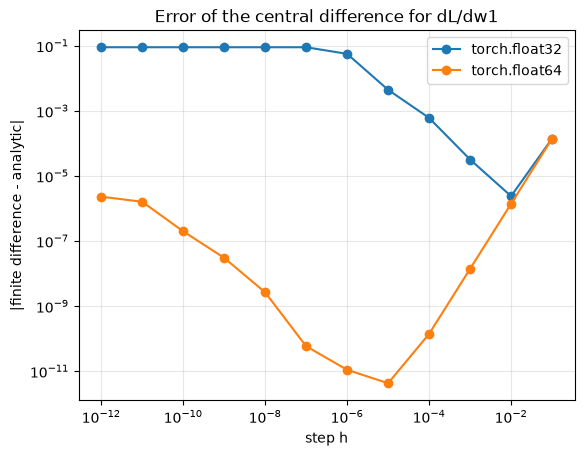

In [13]:
hs = 10.0 ** -np.arange(1, 13)            # h = 1e-1, ..., 1e-12
for dtype in (torch.float32, torch.float64):
    w_ = torch.tensor(2.2, dtype=dtype)
    b_ = torch.tensor(0.0, dtype=dtype)
    errors = []
    for h in hs:
        fd = (bce_loss(w_ + h, b_, x1, y1) - bce_loss(w_ - h, b_, x1, y1)) / (2 * h)
        errors.append(abs(fd.item() - dw_an))   # compare with the float64 analytic value
    plt.loglog(hs, errors, "o-", label=str(dtype))

plt.xlabel("step h")
plt.ylabel("|finite difference - analytic|")
plt.title("Error of the central difference for dL/dw1")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

The error is the sum of the two terms described in Materials 1.2. The **truncation error** of the central difference is $\approx \frac{h^2}{6}|L'''|$, so for large $h$ the curve goes down with slope 2 (each decade of $h$ gives two decades less error: $1.4\cdot10^{-4}, 1.4\cdot10^{-6}, \dots$). The **rounding error** comes from cancellation: $L(w\pm h)$ each carry an absolute error of about $\varepsilon|L|$, their difference becomes tiny, and dividing by $2h$ magnifies the error to $\approx \varepsilon|L|/h$, a line of slope $-1$. Minimising $\frac{h^2}{6}|L'''| + \varepsilon|L|/h$ gives the optimum $h \sim \varepsilon^{1/3}$: about $10^{-5}$ (error $\sim 4\cdot10^{-12}$) for `float64` ($\varepsilon \approx 2.2\cdot10^{-16}$) and about $10^{-2}$ (error $\sim 2\cdot10^{-6}$) for `float32` ($\varepsilon \approx 1.2\cdot10^{-7}$). For $h \le 10^{-7}$ in `float32`, $w+h$ rounds to $w$ itself (the gap between floats near 2.2 is $2.4\cdot10^{-7}$), the difference is exactly 0 and the error is flat at $|\partial L/\partial w_1| = 0.09$.

In [14]:
w = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)

bce_loss(w, b, x1, y1).backward()     # first loss
print("after 1st backward:", w.grad.item())
bce_loss(w, b, x1, y1).backward()     # second, freshly built loss
print("after 2nd backward:", w.grad.item())

w.grad = None                          # what optimizer.zero_grad() does
bce_loss(w, b, x1, y1).backward()
print("after reset + backward:", w.grad.item())

L = bce_loss(w, b, x1, y1)
L.backward()
try:
    L.backward()                       # second backward through the SAME graph
except RuntimeError as e:
    print("same loss twice -> RuntimeError:", str(e)[:70], "...")

after 1st backward: -0.08982628100775408
after 2nd backward: -0.17965256201550817
after reset + backward: -0.08982628100775408
same loss twice -> RuntimeError: Trying to backward through the graph a second time (or directly access ...


`backward()` **adds** the new gradient to whatever is already stored in `.grad`, it does not overwrite it. After the second call `w.grad` is exactly twice the true gradient. This is intentional (it allows summing gradients over several mini-batches), but it is why every training step must call `optimizer.zero_grad()` (or set `.grad = None`) before `backward()` (Materials 1.2, *The rules you need*). This is different from calling `backward()` twice on the *same* loss: PyTorch frees the graph after the first backward pass, so the second call raises an error unless `retain_graph=True` was passed. Rebuilding the loss creates a new graph, which is why the two fresh losses work.

### 1.3 Linear regression

Default data: $N = 200$, $d = 3$, $\mathbf{x} \sim \mathcal{N}(\mathbf{0}, \operatorname{diag}(1, 4, 0.25))$, $y = \mathbf{w}^{\ast\top}\mathbf{x} + b^\ast + 0.1\,\varepsilon$ with $\mathbf{w}^\ast, b^\ast$ of your choice.

- Minimise the mean squared error by least squares, and by full-batch gradient descent twice: in NumPy with the gradient derived by hand, and in PyTorch with autograd and `torch.optim.SGD`. Compare the three solutions.
- Find the largest learning rate for which the loss still decreases over 300 steps, experimentally (two significant digits) and from the Hessian. Compare.

**What I do** (background: Materials 1.3 — *The exact solution*, *Gradients of vector expressions*, *Gradient descent*, *How large can the learning rate be?*, *Random numbers*)

Append a column of ones to $X$ so the bias becomes the last weight: $\hat y = X_a\theta$, $\theta = (\mathbf w, b)$. Then

$$\text{MSE}(\theta) = \frac1N\|X_a\theta - y\|^2 = \frac1N\big(\theta^\top X_a^\top X_a\theta - 2\,(X_a^\top y)^\top\theta + y^\top y\big).$$

With the two rules of Materials 1.3, $\nabla(\mathbf a^\top\theta) = \mathbf a$ and $\nabla(\theta^\top A\theta) = (A + A^\top)\theta$ (here $A = X_a^\top X_a$ is symmetric):

$$\nabla\text{MSE} = \frac2N X_a^\top(X_a\theta - y),\qquad H = \nabla^2\text{MSE} = \frac2N X_a^\top X_a .$$

The gradient is the residuals $X_a\theta - y$ weighted by the inputs.

1. Generate the default data ($\mathbf w^\ast = (1.5, -2, 0.5)$, $b^\ast = 0.7$).
2. Solve exactly with `np.linalg.lstsq` (QR/SVD based, better conditioned than solving the normal equations directly — Materials 1.3).
3. Gradient descent in NumPy with the hand-derived gradient (start at 0, lr 0.1, 300 steps).
4. The same in PyTorch: `nn.Linear` + `F.mse_loss` + `torch.optim.SGD`.
5. Scan learning rates and keep the largest one for which the loss after 300 steps is below the initial loss.
6. Theory: with $e_k = \theta_k - \theta^\ast$, one GD step gives $e_{k+1} = (I - \eta H)e_k$ (Materials 1.3). In the eigenbasis of $H$ each component is multiplied by $(1-\eta\lambda_i)$ per step, so all components shrink iff $|1-\eta\lambda_i| < 1$ for every $i$, i.e. $0 < \eta < 2/\lambda_{\max}$.

In [15]:
rng = np.random.default_rng(0)
N, d = 200, 3
X = rng.standard_normal((N, d)) * np.sqrt([1.0, 4.0, 0.25])   # std = sqrt(variance), broadcast over rows
w_true, b_true = np.array([1.5, -2.0, 0.5]), 0.7
y = X @ w_true + b_true + 0.1 * rng.standard_normal(N)
Xa = np.hstack([X, np.ones((N, 1))])                      # bias column

# 1) least squares
theta_ls = np.linalg.lstsq(Xa, y, rcond=None)[0]

# 2) gradient descent in NumPy, gradient derived by hand
def gd_numpy(lr, steps=300):
    theta = np.zeros(d + 1)
    losses = []
    for _ in range(steps):
        r = Xa @ theta - y                  # residuals
        losses.append(np.mean(r ** 2))
        theta -= lr * 2 / N * Xa.T @ r      # theta <- theta - lr * gradient
    losses.append(np.mean((Xa @ theta - y) ** 2))
    return theta, losses

theta_np, _ = gd_numpy(lr=0.1)

# 3) gradient descent in PyTorch with autograd and SGD
Xt, yt = torch.from_numpy(X), torch.from_numpy(y)       # float64 tensors
model = nn.Linear(d, 1, dtype=torch.float64)
nn.init.zeros_(model.weight)
nn.init.zeros_(model.bias)                              # same start as NumPy
opt = torch.optim.SGD(model.parameters(), lr=0.1)
for _ in range(300):
    loss = F.mse_loss(model(Xt).squeeze(1), yt)
    opt.zero_grad()
    loss.backward()
    opt.step()
theta_torch = np.append(model.weight.detach().numpy().ravel(), model.bias.item())

print("            w1        w2        w3        b")
print("true    ", np.round(np.append(w_true, b_true), 6))
print("lstsq   ", np.round(theta_ls, 6))
print("GD numpy", np.round(theta_np, 6))
print("GD torch", np.round(theta_torch, 6))
print("max |numpy - lstsq| =", np.abs(theta_np - theta_ls).max())
print("max |torch - numpy| =", np.abs(theta_torch - theta_np).max())

            w1        w2        w3        b
true     [ 1.5 -2.   0.5  0.7]
lstsq    [ 1.491002 -2.004808  0.510605  0.696386]
GD numpy [ 1.491002 -2.004808  0.510605  0.696386]
GD torch [ 1.491002 -2.004808  0.510605  0.696386]
max |numpy - lstsq| = 3.3541030863837307e-07
max |torch - numpy| = 0.0


All three solutions agree to about $10^{-7}$ and are close to the true parameters (differences of order 0.01 come from the noise $0.1\varepsilon$, not from the methods). Least squares solves the normal equations exactly; gradient descent reaches the same minimum because the MSE is a convex quadratic, and 300 steps are enough: the slowest direction (eigenvalue 0.469) shrinks by $(1 - 0.1\cdot0.469)^{300} \approx 5\cdot10^{-7}$. NumPy and PyTorch give bit-identical results, since autograd computes the same gradient $\frac2N X_a^\top(X_a\theta-y)$ and `SGD` performs the same update $\theta \leftarrow \theta - \text{lr}\cdot\nabla$.

Hessian eigenvalues: [0.469 1.905 2.16  7.994]
largest lr, experiment: 0.25
largest lr, 2/lambda_max: 0.2502


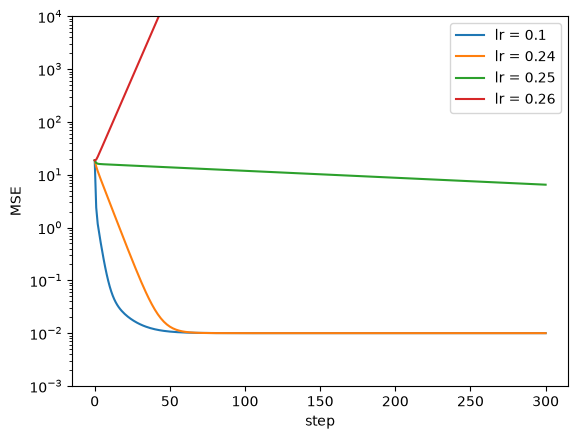

In [16]:
# experiment: largest lr whose loss after 300 steps is still below the initial loss
lrs = np.round(np.arange(0.01, 1.0, 0.001), 3)
good = []
with np.errstate(over="ignore", invalid="ignore"):   # diverging runs overflow; that is expected
    for lr in lrs:
        losses = gd_numpy(lr)[1]
        if losses[-1] < losses[0]:
            good.append(lr)
lr_exp = max(good)

# theory: GD on a quadratic is stable iff lr < 2 / largest eigenvalue of the Hessian
H = 2 / N * Xa.T @ Xa
eig = np.linalg.eigvalsh(H)
lr_theory = 2 / eig.max()

print("Hessian eigenvalues:", np.round(eig, 3))
print(f"largest lr, experiment: {lr_exp:.2g}")
print(f"largest lr, 2/lambda_max: {lr_theory:.4f}")

# loss curves just below and just above the bound
for lr in [0.1, 0.24, 0.25, 0.26]:
    plt.semilogy(gd_numpy(lr)[1], label=f"lr = {lr}")
plt.xlabel("step")
plt.ylabel("MSE")
plt.ylim(1e-3, 1e4)
plt.legend()
plt.show()

The largest Hessian eigenvalue, $\approx 8 = 2\cdot\operatorname{Var}(x_2)$, comes from the feature with variance 4, so the bound is $2/\lambda_{\max} = 0.2502$; the experiment gives 0.25, in agreement. The loss curves show the three regimes of the recursion $e_{k+1} = (I-\eta H)e_k$: at lr 0.24 the top component is multiplied by $|1 - 0.24\cdot 8| = 0.92$ per step and converges (oscillating in sign); at 0.25 the factor is $0.999$, so the loss decreases only very slowly; at 0.26 it is $1.08$ and the loss explodes (the overflowing runs during the scan). Even at lr 0.1 the speed is limited by the smallest eigenvalue 0.469: the condition number $\lambda_{\max}/\lambda_{\min} \approx 17$ comes from the very different feature scales, which is why features are usually standardised (Materials 1.3).

### 1.4 A multilayer network

- Implement `count_parameters` and an MLP as an `nn.Module` built from a list of layer sizes, with ReLU between layers. For sizes `[50, 30, 20, 3]`, check the count (2213) against a sum written by hand.
- Implement a softmax without `torch.softmax` that stays finite for the logits `[1000., 1001., 999.]`.

**What I do** (background: Materials 1.4 — *Layers*, *Modules*, *From logits to probabilities*; signature of `count_parameters` from Appendix A)

1. `count_parameters`: loop over `model.parameters()` and add up `p.numel()` (number of scalars), skipping frozen ones if `trainable_only`.
2. `MLP`: a `Linear` layer for each pair of consecutive sizes, with a `ReLU` after every layer except the last, all in an `nn.Sequential`.
3. Check: a `Linear(n_in, n_out)` has $n_{in}n_{out}$ weights and $n_{out}$ biases (Materials 1.4); also print every parameter tensor with `named_parameters()`.
4. Stable softmax: use the identity $\operatorname{softmax}(\mathbf z) = \operatorname{softmax}(\mathbf z - c\mathbf 1)$ (Materials 1.4) with $c = \max_k z_k$, and compare with `torch.softmax` using `torch.allclose`.

In [17]:
def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    """Number of (trainable) scalar parameters of `model`."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

In [18]:
class MLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        layers = []
        for i in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:          # no ReLU after the output layer
                layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

mlp = MLP([50, 30, 20, 3])
print(mlp)
by_hand = (50 * 30 + 30) + (30 * 20 + 20) + (20 * 3 + 3)
for name, p in mlp.named_parameters():
    print(f"{name:14s} {tuple(p.shape)}  {p.numel()}")
print("count_parameters:", count_parameters(mlp), "  by hand:", by_hand)

mlp.net[0].requires_grad_(False)            # freeze the first layer
print("trainable after freezing layer 1:", count_parameters(mlp),
      "  all:", count_parameters(mlp, trainable_only=False))

MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)
net.0.weight   (30, 50)  1500
net.0.bias     (30,)  30
net.2.weight   (20, 30)  600
net.2.bias     (20,)  20
net.4.weight   (3, 20)  60
net.4.bias     (3,)  3
count_parameters: 2213   by hand: 2213
trainable after freezing layer 1: 683   all: 2213


The three layers have 1530, 620 and 63 parameters, together 2213, matching `count_parameters`. Freezing the first layer (`requires_grad=False`) removes its 1530 parameters from the trainable count but not from the total, which shows the `trainable_only` flag works.

In [19]:
def softmax(z):
    z = z - z.max(dim=-1, keepdim=True).values   # largest logit becomes 0
    e = torch.exp(z)
    return e / e.sum(dim=-1, keepdim=True)

logits = torch.tensor([1000., 1001., 999.])
print("naive :", torch.exp(logits) / torch.exp(logits).sum())
print("stable:", softmax(logits))
print("torch :", torch.softmax(logits, dim=-1))
print("allclose:", torch.allclose(softmax(logits), torch.softmax(logits, dim=-1)))

naive : tensor([nan, nan, nan])
stable: tensor([0.2447, 0.6652, 0.0900])
torch : tensor([0.2447, 0.6652, 0.0900])
allclose: True


$e^{z}$ overflows `float32` for $z > 88.7$ (max ≈ $3.4\cdot10^{38} \approx e^{88.7}$, Materials 1.4), so $e^{1000}$ becomes `inf` and `inf/inf = nan`. **Why $c = \max_k z_k$:** after subtracting it, every shifted logit is $\le 0$, so every exponential is in $(0, 1]$ and nothing can overflow; and the largest one is exactly $e^0 = 1$, so the denominator is at least 1 and can never underflow to 0 (which would give $0/0$ for very negative logits). Here the shifted logits are `[-1, 0, -2]`, and the result agrees with `torch.softmax`. The same shift inside the logarithm gives the stable log-sum-exp used by `F.cross_entropy`, which is why models return logits.

## Lab 2

### 2.1 `Dataset` and `DataLoader`

Default data: four classes in the plane, 150 points each, centres $(\pm 2, \pm 2)$, $\mathbf{x} = \boldsymbol\mu_c + 0.9\,\boldsymbol\epsilon$.

- Write a `Dataset`, split it 60/20/20 with a fixed seed, and build the three `DataLoader`s. Explain why only the training loader is shuffled.

**What I do** (background: Materials 2.1 — *The two classes*, *Splitting the data*, *The default data: Gaussian blobs*)

1. `Blobs` dataset: labels `0..3` (150 each); each point is its class centre plus Gaussian noise with std 0.9. `__len__` and `__getitem__` are all a `Dataset` needs. Labels are `int64`, as cross-entropy requires.
2. `random_split` with fractions `[0.6, 0.2, 0.2]` and a seeded generator → 360/120/120 points.
3. Three `DataLoader`s with batch size 32; only the training one has `shuffle=True`.

360 120 120


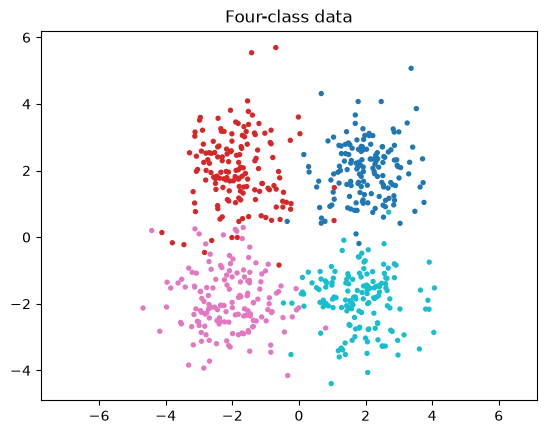

In [20]:
class Blobs(Dataset):
    def __init__(self, n_per_class=150, seed=0):
        g = torch.Generator().manual_seed(seed)
        centres = torch.tensor([[2., 2.], [-2., 2.], [-2., -2.], [2., -2.]])
        self.y = torch.arange(4).repeat_interleave(n_per_class)          # 0,0,...,1,1,...,3
        self.X = centres[self.y] + 0.9 * torch.randn(len(self.y), 2, generator=g)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

blobs = Blobs()
train_set, val_set, test_set = random_split(blobs, [0.6, 0.2, 0.2],
                                            generator=torch.Generator().manual_seed(42))
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)
print(len(train_set), len(val_set), len(test_set))

plt.scatter(blobs.X[:, 0], blobs.X[:, 1], c=blobs.y, s=8, cmap="tab10")
plt.title("Four-class data")
plt.axis("equal")
plt.show()

Shuffling the training data gives different mini-batches every epoch, so the gradient estimates are not correlated with the data order (here the dataset is sorted by class — without shuffling, whole batches could contain one class only and SGD would zig-zag). Validation and test loaders are only used to *measure* the model: the mean loss/accuracy over the whole set does not depend on the order, so shuffling would add nothing, and a fixed order makes evaluations reproducible. Following Materials 2.1, the validation set is used for choices (here: SGD vs Adam in Task 2.2) and the test set only once, for the final model.

### 2.2 The training loop

- Implement `compute_loss`, `compute_accuracy` and `train`.
- Train your MLP once with SGD and once with Adam (default: sizes `[2, 30, 20, 4]`, batch size 32, 30 epochs) and plot both validation-loss curves. Pick the run with the lower final validation loss and report its test accuracy.
- Save its `state_dict`, load it into a new model, and show that it gives the same outputs.

**What I do** (background: Materials 2.2 — *The loss for classification*, *The loop*, *Evaluating over a whole loader*, *Optimisers*, *Saving and loading*, *Devices*; exact specification of the three functions in Appendix A)

1. `compute_loss` / `compute_accuracy`: switch to `eval()` mode and `no_grad()`, loop over the loader, flatten logits to `(-1, C)` and targets to `(-1,)` (so both `(B, C)` and `(B, T, C)` work), add up the *summed* loss or the number of correct argmax predictions, and divide by the total number of predictions (an exact mean even if the last batch is smaller).
2. `train`: for each epoch, put the model in `train()` mode, and for each batch do the standard step `zero_grad → forward → loss → backward → step`. The training loss of an epoch is the mean of the batch losses seen during that epoch; the validation loss is computed with `compute_loss` after the epoch. As specified in Appendix A, `train` expects the model to be on `device` already (it is moved once with `model.to(device)` before the optimiser is created) and moves only the batches.
3. Run the contract check from Appendix A.
4. Train `MLP([2, 30, 20, 4])` with SGD (lr 0.1) and with Adam (lr 0.001, the default; both inside the typical ranges of Materials 2.2), same initial weights, plot validation losses, evaluate the better run on the test set.
5. Save its `state_dict`, load it into a fresh `MLP` (with `torch.load(..., weights_only=True)`) and compare outputs.

In [21]:
def compute_loss(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Mean cross-entropy over all predictions in `loader`.

    Logits may be (B, C) with targets (B,), or (B, T, C) with targets (B, T).
    """
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1),
                                     reduction="sum").item()
            count += y.numel()
    return total / count

In [22]:
def compute_accuracy(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Fraction of correct argmax predictions over all of `loader`."""
    model.eval()
    correct, count = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(dim=-1) == y).sum().item()
            count += y.numel()
    return correct / count

In [23]:
def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    num_epochs: int,
    device: torch.device | str = "cpu",
) -> dict[str, list[float]]:
    """Train with cross-entropy.

    Returns {"train_loss": [...], "val_loss": [...]}, one value per epoch.
    """
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(num_epochs):
        model.train()
        total, count = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * y.numel()     # batch mean -> batch sum
            count += y.numel()
        history["train_loss"].append(total / count)
        history["val_loss"].append(compute_loss(model, val_loader, device))
    return history

Contract check copied from Materials, Appendix A: it tests the signatures, that the loss does not depend on the batch size, the `(B, T, C)` case, and that `train` actually learns.

In [24]:
_g = torch.Generator().manual_seed(0)
_x = torch.randn(40, 3, generator=_g)
_y = (_x[:, 0] > 0).long()
_net = nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 2))
_loader = DataLoader(TensorDataset(_x, _y), batch_size=16)

assert count_parameters(_net) == 3 * 8 + 8 + 8 * 2 + 2
_net[0].weight.requires_grad_(False)
assert count_parameters(_net) == 26 and count_parameters(_net, trainable_only=False) == 50
_net[0].weight.requires_grad_(True)

_l16 = compute_loss(_net, _loader)
_l40 = compute_loss(_net, DataLoader(TensorDataset(_x, _y), batch_size=40))
assert isinstance(_l16, float) and abs(_l16 - _l40) < 1e-5, "the loss must not depend on the batch size"
assert 0.0 <= compute_accuracy(_net, _loader) <= 1.0

# logits of shape (B, T, C) with targets (B, T), as in List 5
_seq = nn.Embedding(5, 5)
nn.init.zeros_(_seq.weight)
_tok = torch.randint(0, 5, (12, 7), generator=_g)
assert abs(compute_loss(_seq, DataLoader(TensorDataset(_tok, _tok), batch_size=4)) - math.log(5)) < 1e-5

_h = train(_net, _loader, _loader, torch.optim.Adam(_net.parameters(), lr=0.05), num_epochs=20)
assert set(_h) == {"train_loss", "val_loss"} and len(_h["train_loss"]) == len(_h["val_loss"]) == 20
assert _h["val_loss"][-1] < _h["val_loss"][0] and compute_accuracy(_net, _loader) > 0.9
print("Contract check passed: count_parameters, compute_loss, compute_accuracy, train")

Contract check passed: count_parameters, compute_loss, compute_accuracy, train


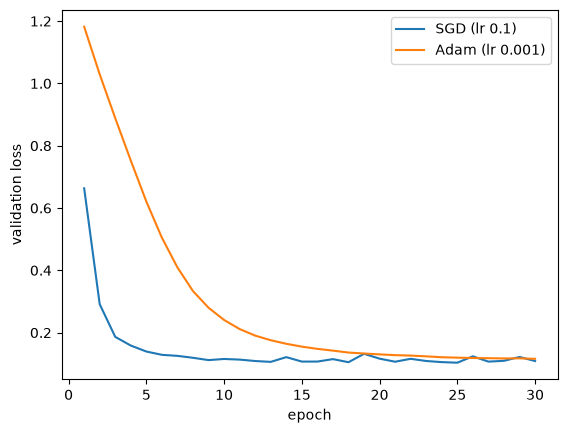

final val loss  SGD: 0.1089   Adam: 0.1160
best run: SGD,  test accuracy = 0.9417


In [25]:
torch.manual_seed(0)
model_sgd = MLP([2, 30, 20, 4])
model_adam = MLP([2, 30, 20, 4])
model_adam.load_state_dict(model_sgd.state_dict())     # identical starting weights

hist_sgd = train(model_sgd, train_loader, val_loader,
                 torch.optim.SGD(model_sgd.parameters(), lr=0.1), num_epochs=30)
hist_adam = train(model_adam, train_loader, val_loader,
                  torch.optim.Adam(model_adam.parameters(), lr=1e-3), num_epochs=30)

plt.plot(range(1, 31), hist_sgd["val_loss"], label="SGD (lr 0.1)")
plt.plot(range(1, 31), hist_adam["val_loss"], label="Adam (lr 0.001)")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

print(f"final val loss  SGD: {hist_sgd['val_loss'][-1]:.4f}   Adam: {hist_adam['val_loss'][-1]:.4f}")
best_name, best = (("SGD", model_sgd) if hist_sgd["val_loss"][-1] < hist_adam["val_loss"][-1]
                   else ("Adam", model_adam))
print(f"best run: {best_name},  test accuracy = {compute_accuracy(best, test_loader):.4f}")

SGD (lr 0.1) drops quickly in the first few epochs and then fluctuates around 0.11; Adam with its default lr 0.001 takes much smaller steps and needs about 20 epochs to reach the same level. Both end close together; SGD has the lower final validation loss (0.109 vs 0.116), so it is selected, and its **test accuracy is 94.2%**. The remaining errors are expected: with noise std 0.9 the four clouds overlap near the axes, so even the ideal classifier (the four quadrants) misclassifies some points.

In [26]:
torch.save(best.state_dict(), "best_mlp.pt")

loaded = MLP([2, 30, 20, 4])                      # new model with random weights
loaded.load_state_dict(torch.load("best_mlp.pt", weights_only=True))
loaded.eval()
best.eval()

x_test = blobs.X[test_set.indices]
with torch.no_grad():
    print("identical outputs:", torch.equal(best(x_test), loaded(x_test)))

identical outputs: True


The `state_dict` is a dictionary of all parameter tensors (weights and biases, by layer name). Loading it into a freshly constructed model with the same architecture restores exactly the same numbers, so the outputs on the test set are bit-for-bit identical (`torch.equal` is `True`). Only the weights are saved, not the class, so the code that builds `MLP([2, 30, 20, 4])` is still needed (Materials 2.2, *Saving and loading*).

### 2.3 A count-based bigram model

Default text: `the-verdict.txt`. Tokens are characters; build the vocabulary from the whole text and use the last 10% for validation.

- Report training and validation perplexity for $\alpha \in \{0, 0.01, 0.1, 1, 10\}$ (report `inf` where it occurs) and explain both ends. On the default text, expect a validation perplexity of about 12 for $\alpha = 1$.
- Generate 200 characters from the $\alpha = 1$ model.

**What I do** (background: Materials 2.3 — *Tokens as integers*, *The bigram model*, *Perplexity*, *Counting and evaluating without loops*, *Generating text*, *The default text*)

1. Read the text (download link in Materials 2.3; the file must be next to this notebook), build the character vocabulary from the whole text (`stoi`: char → index, `itos`: index → char) and encode the text as a tensor of indices. First 90% = training, last 10% = validation — the *end* of the text rather than random characters, because neighbouring characters are dependent and a random split would leak training information into validation (Materials 2.3).
2. Count bigrams on the training part: the pair (current $i$, next $j$) is turned into one number $iV + j$, `torch.bincount` counts them, and the result is reshaped to a $V\times V$ matrix `counts[i, j]`.
3. Smoothed probabilities: $P(j\mid i) = \dfrac{\text{counts}[i,j] + \alpha}{\sum_k \text{counts}[i,k] + V\alpha}$.
4. Perplexity $= \exp\big(-\frac1n\sum \log P(x_{t+1}\mid x_t)\big)$ over all consecutive pairs of a sequence.
5. Generation: start from a character, repeatedly sample the next one from the row $P(\cdot\mid \text{current})$ with `torch.multinomial`.

In [27]:
from pathlib import Path

text = Path("the-verdict.txt").read_text(encoding="utf-8")
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])

n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"{len(text)} characters, vocabulary size V = {V}, train {len(train_data)}, val {len(val_data)}")

counts = torch.bincount(train_data[:-1] * V + train_data[1:], minlength=V * V).view(V, V).float()

def bigram_probs(alpha):
    smoothed = counts + alpha
    return smoothed / smoothed.sum(dim=1, keepdim=True)

def perplexity(P, seq):
    nll = -torch.log(P[seq[:-1], seq[1:]]).mean()
    return torch.exp(nll).item()

print(" alpha   train ppl   val ppl")
for alpha in [0, 0.01, 0.1, 1, 10]:
    P = bigram_probs(alpha)
    print(f"{alpha:6}   {perplexity(P, train_data):9.3f}   {perplexity(P, val_data):7.3f}")

20479 characters, vocabulary size V = 62, train 18431, val 2048
 alpha   train ppl   val ppl
     0      10.879       inf
  0.01      10.897    11.093
   0.1      11.035    11.024
     1      11.955    11.788
    10      17.117    16.757


With $\alpha = 0$ (pure relative frequencies) the training perplexity is the lowest possible (10.88), but the validation perplexity is `inf`: the validation text contains at least one bigram never seen in training, which gets probability 0 and $-\log 0 = \infty$. A small $\alpha$ gives every bigram a non-zero probability, which removes the infinity at almost no cost on the training set; the best validation value here is $\approx 11.0$ at $\alpha = 0.1$, and $\alpha = 1$ gives 11.8 (the expected ≈ 12). At the other end, large $\alpha$ (10) overwhelms the counts (many rows have only a few observations against $V\alpha = 620$ pseudo-counts), pulling every row towards the uniform distribution (perplexity $V = 62$), so both perplexities grow: this is underfitting. Training perplexity rises monotonically with $\alpha$, because $\alpha = 0$ is exactly the maximum-likelihood fit to the training data.

In [28]:
P = bigram_probs(1)
g = torch.Generator().manual_seed(0)
ix = stoi["T"]
out = ["T"]
for _ in range(200):
    ix = torch.multinomial(P[ix], 1, generator=g).item()   # sample next char from row ix
    out.append(itos[ix])
print("".join(out))

Tw?is.
T!"THEE'd'endoo IvPple d"-imeicavSdefequ


ojus Ipateney cowe win.J

geatheldit ioss Pm hist pt thin
"-powan-Y(zs, yse t toud mourmyCheered ft oroslironl lit ty poradhes-recked pt, tunovm.
b! ou


The sample has word-like chunks, spaces in plausible places and frequent letter pairs ("th", "he", "an"), but no real words or grammar: a bigram model only knows which character tends to follow the current one and has no memory of anything earlier.

### 2.4 A neural bigram model

- Train a table of logits $W \in \mathbb{R}^{V \times V}$ (`nn.Embedding(V, V)`) on the (current, next) character pairs with your `train` (default: batch size 256, Adam with learning rate 0.1, 5 epochs). Compare its validation perplexity with your best count-based model from Task 2.3 and explain the result.
- Compare the loss before training with $\ln V$. Explain the difference, and show that zero-initialised logits give exactly $\ln V$.
- Show with an experiment what plays the role of $\alpha$ (for example more epochs, or weight decay).

**What I do** (background: Materials 2.4 — *The same model, learned by gradient descent*, *Embeddings*, *Training data*, *Regularisation*)

1. Make (current, next) pairs from the training and validation sequences with `TensorDataset`, and loaders with batch size 256.
2. `nn.Embedding(V, V)` maps a character index to a row of $V$ logits — exactly a learnable bigram table $W$; `softmax(W[i])` is $P(\cdot\mid i)$. Because the model returns logits of shape `(B, V)`, my `train`, `compute_loss` from Task 2.2 work unchanged.
3. Evaluate before training, train 5 epochs with Adam (lr 0.1), report validation perplexity $= e^{\text{val loss}}$.
4. Compare the initial loss with $\ln V$; repeat with all-zero logits.
5. Experiment for the role of $\alpha$, using the regularisers listed in Materials 2.4: **weight decay** with `torch.optim.AdamW` (shrinks the logits by a factor $1-\eta\lambda$ per step, i.e. towards 0 = the uniform distribution) and **early stopping** (the number of epochs). Both start from zero logits, the uniform model, so the starting point corresponds to $\alpha = \infty$.

In [29]:
train_pairs = TensorDataset(train_data[:-1], train_data[1:])
val_pairs = TensorDataset(val_data[:-1], val_data[1:])
train_loader_bg = DataLoader(train_pairs, batch_size=256, shuffle=True)
val_loader_bg = DataLoader(val_pairs, batch_size=256)

torch.manual_seed(0)
bigram = nn.Embedding(V, V)                    # W: V x V table of logits, init N(0, 1)
loss_before = compute_loss(bigram, val_loader_bg)

hist_bg = train(bigram, train_loader_bg, val_loader_bg,
                torch.optim.Adam(bigram.parameters(), lr=0.1), num_epochs=5)

best_count_ppl = min(perplexity(bigram_probs(a), val_data) for a in [0.01, 0.1, 1, 10])
print("val loss per epoch:", np.round(hist_bg["val_loss"], 4))
print(f"neural bigram     val perplexity: {math.exp(hist_bg['val_loss'][-1]):.3f}")
print(f"best count-based  val perplexity: {best_count_ppl:.3f}")

val loss per epoch: [2.4395 2.4139 2.4181 2.4271 2.4114]
neural bigram     val perplexity: 11.150
best count-based  val perplexity: 11.024


The neural model reaches a validation perplexity of 11.15, very close to the best count-based model (11.02). This is expected (Materials 2.4): every row of $\operatorname{softmax}(W_i)$ can represent any positive distribution, so this is the same model family, and minimising the cross-entropy is the same maximum-likelihood problem whose solution is the relative counts. Unlike $\alpha=0$ it does not give `inf`: a finite number of steps only pushes the logits of unseen bigrams down by a finite amount, and where training starts (here random $\mathcal N(0,1)$ logits) determines where it ends — the initialisation itself acts as a regulariser. It is slightly worse than the tuned count model because Adam with lr 0.1 is noisy (the validation loss oscillates between epochs) and this implicit smoothing is not tuned.

In [30]:
zero = nn.Embedding(V, V)
nn.init.zeros_(zero.weight)                    # all logits 0 -> uniform distribution

print(f"ln V                       = {math.log(V):.4f}")
print(f"loss before training (N(0,1) init) = {loss_before:.4f}")
print(f"loss with zero logits      = {compute_loss(zero, val_loader_bg):.4f}")

ln V                       = 4.1271
loss before training (N(0,1) init) = 4.7831
loss with zero logits      = 4.1271


With all logits equal, the softmax is uniform, $P = 1/V$ for every character, so the loss is exactly $-\log(1/V) = \ln V = 4.127$. `nn.Embedding` initialises the table with $\mathcal N(0,1)$ entries, so the initial model makes *confident random* predictions; on average this is worse than uniform. For Gaussian logits with variance $\sigma^2$, $\mathbb E[\log\sum_j e^{z_j}] \approx \ln V + \sigma^2/2$ while the correct logit has mean 0, so the loss is about $\ln V + 0.5$; we observe 4.78, i.e. 0.66 above $\ln V$ (the extra comes from fluctuations of the log-sum-exp over only 62 terms).

In [31]:
def run(weight_decay=0.0, epochs=5):
    torch.manual_seed(0)
    m = nn.Embedding(V, V)
    nn.init.zeros_(m.weight)                   # start from uniform (like alpha = infinity)
    opt = torch.optim.AdamW(m.parameters(), lr=0.1, weight_decay=weight_decay)   # wd=0 must be explicit
    h = train(m, train_loader_bg, val_loader_bg, opt, epochs)
    return math.exp(compute_loss(m, train_loader_bg)), math.exp(h["val_loss"][-1])

print("weight decay   train ppl   val ppl   (AdamW, 5 epochs)")
for wd in [0, 0.01, 0.03, 0.1, 0.3]:
    tr, va = run(weight_decay=wd)
    print(f"{wd:12g}   {tr:9.3f}   {va:7.3f}")

print()
print("epochs   train ppl   val ppl   (no weight decay)")
for ep in [1, 5, 20]:
    tr, va = run(epochs=ep)
    print(f"{ep:6d}   {tr:9.3f}   {va:7.3f}")

weight decay   train ppl   val ppl   (AdamW, 5 epochs)
           0      11.093    11.292
        0.01      11.135    11.268
        0.03      11.243    11.302
         0.1      11.699    11.649
         0.3      13.710    13.568

epochs   train ppl   val ppl   (no weight decay)
     1      11.414    11.407
     5      11.093    11.292
    20      11.076    11.377


**Weight decay plays the role of $\alpha$.** AdamW shrinks every logit by the factor $1-\eta\lambda$ per step, pulling the rows towards uniform distributions, just like adding $\alpha$ pseudo-counts to every cell. As Materials 2.4 warns, with only ~360 steps $\lambda$ must be around $10^{-2}$ or larger to matter: $\lambda = 0.01$ slightly *improves* validation perplexity (11.27 vs 11.29, like a small $\alpha$), $\lambda = 0.1$ behaves like $\alpha \approx 1$ (11.65 vs 11.79), and $\lambda = 0.3$ already oversmooths (13.6), with the training perplexity rising monotonically exactly as with growing $\alpha$. **Early stopping** works the same way from the other side: starting from zero logits (uniform, $\alpha = \infty$), few epochs keep the model close to uniform, and more epochs move the training perplexity down towards the unsmoothed $\alpha=0$ value 10.88 (11.41 → 11.09 → 11.08), while the validation perplexity stops improving after a few epochs.

### 2.5 Your own experiment

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 2.5.

**Question** (first idea of Materials 2.5): how much does the perplexity drop when going from bigrams to **trigrams** (counting, two previous characters as context), and what happens to the gap between training and validation and to the best smoothing $\alpha$?

**What I do**

1. Generalise the counting of Task 2.3 to an $n$-gram model: the $n-1$ previous characters are encoded as one integer $c = x_{t-n+1}V^{n-2} + \dots + x_{t-1}$ (base-$V$ digits, the same trick as $iV + j$ in Materials 2.3), so the table has $V^{n-1}$ rows (62 for bigrams, 3 844 for trigrams) and $V$ columns.
2. For $n = 2, 3$ and 30 values of $\alpha \in [10^{-3}, 10^{2}]$ compute training and validation perplexity.
3. Plot all four curves against $\alpha$ on a log axis and report the best validation perplexity of each model.

2-gram: best alpha = 0.053,  val ppl = 11.01,  train ppl there = 10.97
3-gram: best alpha = 0.0356,  val ppl = 7.06,  train ppl there = 5.97


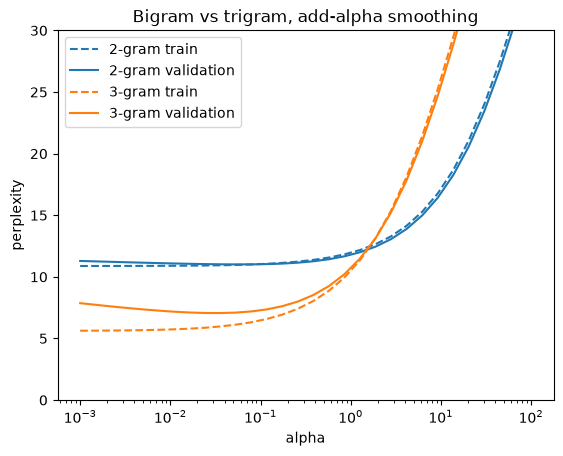

In [32]:
def ngram_perplexities(n, alpha):
    def contexts(seq):
        # one integer per position: the n-1 previous characters as base-V digits
        m = len(seq) - n + 1
        ctx = torch.zeros(m, dtype=torch.long)
        for k in range(n - 1):
            ctx = ctx * V + seq[k : k + m]
        return ctx, seq[n - 1:]                      # (context, next character)

    ctx, nxt = contexts(train_data)
    counts = torch.bincount(ctx * V + nxt, minlength=V ** n).view(V ** (n - 1), V).float()
    P = (counts + alpha) / (counts + alpha).sum(dim=1, keepdim=True)

    def ppl(seq):
        c, x = contexts(seq)
        return math.exp(-torch.log(P[c, x]).mean().item())
    return ppl(train_data), ppl(val_data)

alphas = np.logspace(-3, 2, 30)
for n, colour in [(2, "C0"), (3, "C1")]:
    res = np.array([ngram_perplexities(n, a) for a in alphas])
    best = res[:, 1].argmin()
    plt.semilogx(alphas, res[:, 0], "--", color=colour, label=f"{n}-gram train")
    plt.semilogx(alphas, res[:, 1], "-", color=colour, label=f"{n}-gram validation")
    print(f"{n}-gram: best alpha = {alphas[best]:.3g},  val ppl = {res[best, 1]:.2f},  "
          f"train ppl there = {res[best, 0]:.2f}")
plt.xlabel("alpha")
plt.ylabel("perplexity")
plt.ylim(0, 30)
plt.legend()
plt.title("Bigram vs trigram, add-alpha smoothing")
plt.show()

The trigram model is much better: the best validation perplexity drops from 11.0 (bigram, $\alpha \approx 0.05$) to 7.1 (trigram, $\alpha \approx 0.04$), because two characters of context say much more about the next one (e.g. after "th" almost always a vowel). But the **gap between training and validation grows**: for bigrams it is almost zero (11.0 vs 11.0), for trigrams 6.0 vs 7.1. The trigram table has $V^2 = 3\,844$ contexts for only 18 000 training characters, so many contexts are seen a few times or never, and the model starts to memorise the training text. The trigram curves are also more sensitive to $\alpha$: for $\alpha \gtrsim 1.5$ the trigram is even *worse* than the bigram, because each sparse row receives $V\alpha$ pseudo-counts that drown the few real ones. With more context, smoothing becomes more important and must be tuned more carefully on validation data.